# Seoul Bike: regression
Compare validation-tuned XGBoost and LightGBM with frozen TabPFN-3.5-Fast and Mitra v2. Predict **Rented Bike Count** per hour using the same seed-42 random 60/20/20 train/validation/test split for every model. **RMSE** is primary (lower is better); MAE and R² provide context.

This is **retrospective tabular prediction using observed weather**, not future-demand forecasting. Random splitting permits neighboring hours and dates in different partitions. A forecasting claim would require a separate chronological experiment and weather information available at the forecast horizon.

Source: [UCI Seoul Bike Sharing Demand](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand) (2020), [DOI 10.24432/C5F62R](https://doi.org/10.24432/C5F62R), **CC BY 4.0**. All 8,760 hourly records and 13 predictors are retained. Archive and CSV hashes pin the source.

In [1]:
from pathlib import Path
import os
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src/benchmark.py").exists())
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from src.benchmark import save_results
from src.data import make_split, RANDOM_STATE
from src.datasets import load_seoul_bike
from src.evaluation import comparison_table
from src.experiments import run_isolated_comparison
from src.features import BikeFeatures
from src.models.classical import make_classical_models, classical_search_spaces
from src.models.tabpfn import make_tabpfn_models
from src.models.mitra import make_mitra_models
from src.plotting import plot_comparison
from src.preprocessing import make_preprocessor

SEED = RANDOM_STATE
PROFILE = os.environ.get("BENCHMARK_PROFILE", "full")  # full or smoke
DEVICE = os.environ.get("BENCHMARK_DEVICE", "auto")  # CUDA for full foundation-model runs
MODEL_TIMEOUT = float(os.environ.get("BENCHMARK_MODEL_TIMEOUT", "300"))
DOWNLOAD_DATA = True
DOWNLOAD_WEIGHTS = False  # Pre-cache pinned weights; see docs/seoul-bike.md.
assert PROFILE in {"full", "smoke"}
OUTPUT = ROOT / "results/seoul-bike" / PROFILE
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"Profile={PROFILE}; device={DEVICE}; per-model budget={MODEL_TIMEOUT:g}s; seed={SEED}")

Profile=full; device=cuda; per-model budget=300s; seed=42


## Load, validate, and split
The loader verifies hashes, schema, finite values, nonnegative integer targets, and the complete ordered hourly sequence from December 2017 through November 2018. It parses `Date` explicitly as day/month/year and represents it as integer days since the fixed Unix epoch, a compatibility conversion used in every setting. Seasons, holiday, and functioning-day indicators are categorical. The target is removed from predictors.

All 295 non-functioning hours remain in the full dataset. There is no target clipping, log transform, rounding, forced-zero rule, or filtering by observed rental counts. The optional **smoke** profile samples 500 rows with seed 42 for execution checks and saves separate artifacts.

In [2]:
X, y, source = load_seoul_bike(download=DOWNLOAD_DATA)
if PROFILE == "smoke":
    selected, _ = train_test_split(np.arange(len(y)), train_size=500, random_state=SEED)
    selected = np.sort(selected)
    X, y = X.iloc[selected].copy(), y.iloc[selected].copy()

splits = make_split(y.to_numpy(), "regression", SEED)
protocol = {"prediction_goal": "retrospective tabular prediction with observed weather",
    "split_method": "random 60/20/20; no stratification", "seed": SEED,
    "forecasting": False, "refit_on_train_plus_validation": False}
split_record = {key: positions.tolist() for key, positions in splits.items()}
(OUTPUT / "splits.json").write_text(json.dumps({"seed": SEED, "profile": PROFILE,
    "protocol": protocol, "source_row_positions": X.index.tolist(), "splits": split_record}, indent=2) + "\n")
display(pd.DataFrame([{"partition": key, "rows": len(positions)}
    for key, positions in splits.items()]).set_index("partition"))
print(f"Predictors: {X.shape[1]}; source non-functioning hours retained: {source['non_functioning_rows']}")
print("Archive SHA-256:", source["archive_sha256"])
print("CSV SHA-256:", source["csv_sha256"])
assert "Rented Bike Count" not in X.columns

,rows
partition,
train,5256
validation,1752
test,1752


Predictors: 13; source non-functioning hours retained: 295
Archive SHA-256: 139e9908f0a3544bb222386855c9ce107e96467306bb8e4ce936aab59e7baac4
CSV SHA-256: 373339b71a8935d69e9af0abf26a70744632119862eeb3919efb389a7b749c60


## Training-data exploration
Explore training predictors and training rental counts only. The source has no missing values or identical full rows. Random partitions are disjoint by source row; neighboring-hour dependence still limits the independence of observations and interpretation of this single split.

,Date,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
4938,17706,18,29.8,35,3.3,1805,12.6,1.15,0.0,0.0,Summer,No Holiday,Yes
3409,17643,1,15.9,39,0.2,2000,1.9,0.00,0.0,0.0,Spring,No Holiday,Yes
6691,17779,19,25.4,55,3.2,2000,15.6,0.15,0.0,0.0,Autumn,No Holiday,Yes
6328,17764,16,30.4,53,2.0,1990,19.7,1.82,0.0,0.0,Summer,No Holiday,Yes
1756,17574,4,-8.6,31,3.5,2000,-22.7,0.00,0.0,0.0,Winter,No Holiday,Yes


,dtype,missing,unique_training_values
Date,int64,0,365
Hour,int64,0,24
Temperature(°C),float64,0,531
Humidity(%),int64,0,88
Wind speed (m/s),float64,0,65
Visibility (10m),int64,0,1554
Dew point temperature(°C),float64,0,539
Solar Radiation (MJ/m2),float64,0,339
Rainfall(mm),float64,0,46
Snowfall (cm),float64,0,43


,count,mean,std,min,25%,50%,75%,max
Date,5256.0,17684.522451,105.242609,17501.0,17594.000,17684.00,17777.0000,17865.00
Hour,5256.0,11.522260,6.865257,0.0,6.000,12.00,17.0000,23.00
Temperature(°C),5256.0,12.939193,11.902740,-17.5,3.675,13.75,22.5250,39.00
Humidity(%),5256.0,58.051750,20.409313,0.0,42.000,57.00,74.0000,98.00
Wind speed (m/s),5256.0,1.735864,1.037008,0.0,1.000,1.50,2.3000,7.40
Visibility (10m),5256.0,1438.497146,611.550354,33.0,940.750,1707.00,2000.0000,2000.00
Dew point temperature(°C),5256.0,4.074182,12.933099,-30.6,-4.400,5.00,14.6000,26.80
Solar Radiation (MJ/m2),5256.0,0.587327,0.881983,0.0,0.000,0.01,0.9725,3.52
Rainfall(mm),5256.0,0.145186,1.034790,0.0,0.000,0.00,0.0000,24.00
Snowfall (cm),5256.0,0.072374,0.442347,0.0,0.000,0.00,0.0000,8.80


,Training rental counts
count,5256.000000
mean,704.526636
std,645.522243
min,0.000000
25%,190.000000
50%,504.000000
75%,1066.250000
max,3404.000000


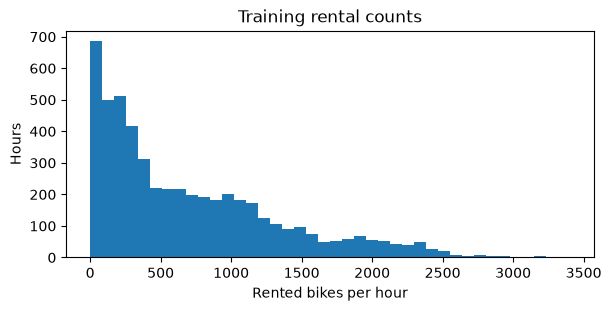

In [3]:
training = X.iloc[splits["train"]]
display(training.head())
display(pd.DataFrame({"dtype": training.dtypes.astype(str), "missing": training.isna().sum(),
    "unique_training_values": training.nunique()}))
display(training.select_dtypes("number").describe().T)
display(y.iloc[splits["train"]].describe().to_frame("Training rental counts"))
figure, axis = plt.subplots(figsize=(6, 3), layout="constrained")
axis.hist(y.iloc[splits["train"]], bins=40)
axis.set(title="Training rental counts", xlabel="Rented bikes per hour", ylabel="Hours")
plt.show()

## Predeclared model and feature settings
Raw foundation-model settings use the 13 source predictors, including Date's fixed numeric representation. The engineered setting keeps them and adds seven label-free calendar features: sine/cosine of hour (24-hour period), weekday (Monday=0), month, weekend indicator, and sine/cosine of day-of-year (365.25-day period). These are row-local calendar functions; no target lags, future aggregates, or learned date origins are used.

Both classical models use engineered features with train-only imputation, encoding, and scaling. Each uses the shared four-candidate, 80-tree validation search, minimizing RMSE. The dummy predicts the training target mean. Foundation models use pinned frozen weights and native train-only preprocessing, without tuning or fine-tuning. TabPFN uses its auto ensemble; Mitra uses one estimator and the distributional head's softmax-weighted bin mean. Every model uses exactly the same observations.

In [4]:
models = {"Dummy mean": DummyRegressor(strategy="mean")}
models.update(make_classical_models("regression", SEED))
models.update(make_tabpfn_models("regression", SEED, DEVICE, download=DOWNLOAD_WEIGHTS))
models.update(make_mitra_models("regression", SEED, DEVICE, download=DOWNLOAD_WEIGHTS))
models["TabPFN - Engineered"] = make_tabpfn_models("regression", SEED, DEVICE, download=DOWNLOAD_WEIGHTS)["TabPFN - Raw"]
models["Mitra v2 - Engineered"] = make_mitra_models("regression", SEED, DEVICE, download=DOWNLOAD_WEIGHTS)["Mitra v2 - Raw"]

# Choosing column names from a transformed training frame learns no holdout information.
engineered_training = BikeFeatures().fit_transform(training)
classical_preprocessor = Pipeline([
    ("features", BikeFeatures()), ("encoding", make_preprocessor(engineered_training)),
])
preprocessors = {name: classical_preprocessor for name in ("XGBoost", "LightGBM")}
preprocessors.update({name: BikeFeatures() for name in ("TabPFN - Engineered", "Mitra v2 - Engineered")})
search_spaces = classical_search_spaces()
for name, model in models.items():
    print(name, "— validation grid" if name in search_spaces else "— fixed inference")

Dummy mean — fixed inference
XGBoost — validation grid
LightGBM — validation grid
TabPFN - Raw — fixed inference
Mitra v2 - Raw — fixed inference
TabPFN - Engineered — fixed inference
Mitra v2 - Engineered — fixed inference


## Execute the comparison
Each independent, predeclared recipe runs in its own process to release model/GPU memory on exit. Selection uses training and validation only; the selected model is then scored on the test partition. Earlier test scores do not alter later recipes. The timeout includes loading, tuning, and prediction. A model that exceeds the budget or available memory is **Not evaluated**, with a reason and no metric values. Inputs are never silently subsampled to make a model run. Unexpected implementation failures remain distinct and fail the notebook after diagnostic artifacts are saved.

In [5]:
results = run_isolated_comparison(
    X, y, models, task="regression", dataset_name=f"Seoul Bike ({PROFILE}, {len(X):,} rows)",
    seed=SEED, splits=splits, search_spaces=search_spaces,
    preprocessors=preprocessors, timeout=MODEL_TIMEOUT, output_path=OUTPUT / "results.json",
)
results["dataset"].update({"profile": PROFILE, "source": source, "source_row_positions": X.index.tolist()})
results["protocol"] = protocol
results["split_method"] = "random"
results["checkpoint_manifest"] = json.loads((ROOT / "checkpoints/manifest.json").read_text())
results["feature_engineering"] = {"added": list(BikeFeatures.added),
    "classical_setting": "engineered", "foundation_settings": ["raw", "engineered"],
    "hour_period": 24, "day_of_year_period": 365.25, "target_transform": "none",
    "prediction_postprocessing": "none"}
save_results(results, OUTPUT / "results.json")

Running Dummy mean...


Dummy mean: evaluated


Running XGBoost...


XGBoost: evaluated


Running LightGBM...


...

Mitra v2 - Raw: evaluated


Running TabPFN - Engineered...


TabPFN - Engineered: evaluated


Running Mitra v2 - Engineered...


Mitra v2 - Engineered: evaluated


## Final test metrics
RMSE and MAE use bikes per hour; R² is unitless and may be negative. Scores are calculated from saved predictions. Predictions are evaluated without clipping or rounding. Empty metric cells indicate an unevaluated model and retain its reason.

In [6]:
status = pd.DataFrame([{"model": row["name"],
    "status": "Evaluated" if row["status"] == "evaluated" else "Not evaluated" if row["status"] == "unavailable" else "Failed",
    "reason": row.get("reason", ""), "seconds": row["elapsed_seconds"]} for row in results["models"]]).set_index("model")
table = comparison_table(results)
export = table.join(status)
export.to_csv(OUTPUT / "metrics.csv")
display(export.style.format({column: "{:.4f}" for column in table.columns}, na_rep="Not evaluated"))
print("Profile:", PROFILE, "—", "full released dataset" if PROFILE == "full" else "SMOKE SAMPLE; not full benchmark results")

,rmse,mae,r2,status,reason,seconds
model,,,,,,
Dummy mean,636.0166,512.7802,-0.0001,Evaluated,,6.149393
XGBoost,179.4589,104.3465,0.9204,Evaluated,,3.903616
LightGBM,182.8140,112.1801,0.9174,Evaluated,,2.966850
TabPFN - Raw,111.7418,59.8627,0.9691,Evaluated,,14.385575
Mitra v2 - Raw,205.1263,112.9967,0.8960,Evaluated,,38.397151
TabPFN - Engineered,104.7439,48.1243,0.9729,Evaluated,,11.925606
Mitra v2 - Engineered,125.4689,55.7599,0.9611,Evaluated,,49.335461


Profile: full — full released dataset


## Primary-metric comparison
The plot shows test RMSE from the measured results (lower is better). All attempted models and any runtime limitations remain in the table.

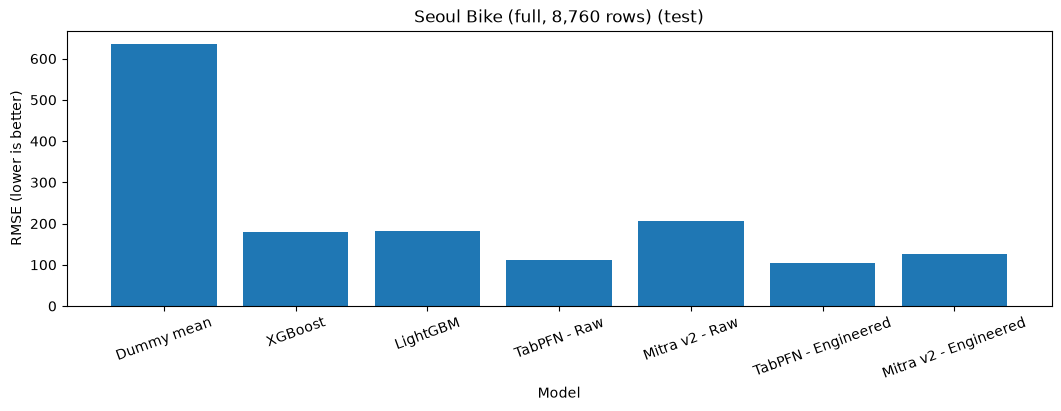

In [7]:
figure = plot_comparison(results)
figure.savefig(OUTPUT / "rmse.png", dpi=150)
plt.show()

## Observations and limitations
This retrospective, single-random-split comparison does not measure future forecasting performance, statistical significance, or universal model superiority. Observed weather and functioning-day status are included as released; weather forecasts and availability at a future prediction horizon are not modeled. Temporal neighbors may span partitions. The one-year source limits conclusions about future seasons or years.

No test-based feature selection, target transformation, threshold rule, tuning, or train-plus-validation refit is performed. Context is training-only and all model weights remain frozen for foundation-model runs. Source/split positions, checksums, model settings, validation trials, predictions, package versions, checkpoint hashes, GPU details, and explicit runtime limits are saved with the results.

In [8]:
ranked = table["rmse"].dropna().sort_values()
if not ranked.empty:
    display(Markdown(f"Lowest observed test RMSE: **{ranked.index[0]}**, **{ranked.iloc[0]:.2f} bikes/hour** ({PROFILE} profile)."))
not_evaluated = status[status["status"] != "Evaluated"]
if not not_evaluated.empty:
    display(not_evaluated[["status", "reason"]])
print("Artifacts:", OUTPUT.relative_to(ROOT))
failed = [row["name"] for row in results["models"] if row["status"] == "failed"]
assert not failed, f"Unexpected model failures require investigation: {failed}"

Lowest observed test RMSE: **TabPFN - Engineered**, **104.74 bikes/hour** (full profile).

Artifacts: results/seoul-bike/full
